In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# 1. LOAD FINAL DATASET

file_path = r"F:\25.2F HND\ML CW\Fish_Price_Prediction\data\processed\fish_price_ready_for_model.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Shape: (978, 9)


,Species,MarketType,Year,MonthNumber,Week,Price_2025,Price_LastWeek,Change_LastYear_%,Price_Current
0,Barracuda(L),Consumer,2026,3,1.0,2170.00,2580.0,14.7,2490.0
1,Big eye scade,Consumer,2026,3,1.0,1133.33,1420.0,15.6,1310.0
2,Cuttle fish,Consumer,2026,3,1.0,2160.00,2200.0,2.3,2210.0
3,Frigate tuna,Consumer,2026,3,1.0,970.00,1315.0,28.9,1250.0
4,Ginnati Paraw,Consumer,2026,3,1.0,1280.00,1680.0,22.7,1570.0


In [4]:
print(df.columns.tolist())
print()
print(df.info())

['Species', 'MarketType', 'Year', 'MonthNumber', 'Week', 'Price_2025', 'Price_LastWeek', 'Change_LastYear_%', 'Price_Current']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 978 entries, 0 to 977
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Species            978 non-null    object 
 1   MarketType         978 non-null    object 
 2   Year               978 non-null    int64  
 3   MonthNumber        978 non-null    int64  
 4   Week               978 non-null    float64
 5   Price_2025         978 non-null    float64
 6   Price_LastWeek     978 non-null    float64
 7   Change_LastYear_%  978 non-null    float64
 8   Price_Current      978 non-null    float64
dtypes: float64(5), int64(2), object(2)
memory usage: 68.9+ KB
None


In [5]:
# 2. DATASET CHECK


print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Number of rows: 978
Number of columns: 9

Missing values:
Species              0
MarketType           0
Year                 0
MonthNumber          0
Week                 0
Price_2025           0
Price_LastWeek       0
Change_LastYear_%    0
Price_Current        0
dtype: int64

Duplicate rows: 0

Data types:
Species               object
MarketType            object
Year                   int64
MonthNumber            int64
Week                 float64
Price_2025           float64
Price_LastWeek       float64
Change_LastYear_%    float64
Price_Current        float64
dtype: object


In [6]:
display(df.describe(include="all"))

,Species,MarketType,Year,MonthNumber,Week,Price_2025,Price_LastWeek,Change_LastYear_%,Price_Current
count,978,978,978.0,978.000000,978.000000,978.000000,978.000000,978.000000,978.000000
unique,31,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Indian Scad,Wholesale,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,53,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,2026.0,4.889571,2.384458,1435.738538,1643.711539,19.144479,1653.560930
std,NaN,NaN,0.0,1.468911,1.118123,797.505295,825.999499,15.949640,835.053969
min,NaN,NaN,2026.0,3.000000,1.000000,3.000000,211.430000,-15.600000,0.000000
25%,NaN,NaN,2026.0,4.000000,1.000000,900.000000,1073.747500,7.625000,1076.250000
50%,NaN,NaN,2026.0,5.000000,2.000000,1251.250000,1473.330000,15.800000,1490.000000
75%,NaN,NaN,2026.0,6.000000,3.000000,1923.750000,2088.332500,26.400000,2132.140000


In [10]:
# 3: SELECT FEATURES AND TARGET

features = [
    "Year",
    "MonthNumber",
    "Week",
    "MarketType",
    "Species",
    "Price_2025",
    "Price_LastWeek"
]

target = "Price_Current"

# Select input features
X = df[features].copy()

# Select target
y = df[target].copy()

print("Features selected:")
for feature in features:
    print("-", feature)

print("\nTarget selected:")
print("-", target)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features selected:
- Year
- MonthNumber
- Week
- MarketType
- Species
- Price_2025
- Price_LastWeek

Target selected:
- Price_Current

X shape: (978, 7)
y shape: (978,)


In [11]:
# CHECK MISSING VALUES


print("Missing values in selected features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in selected features:
Year              0
MonthNumber       0
Week              0
MarketType        0
Species           0
Price_2025        0
Price_LastWeek    0
dtype: int64

Missing values in target:
0


In [12]:
# CHECK DATA TYPES

print(X.dtypes)
print("\nTarget datatype:")
print(y.dtype)

Year                int64
MonthNumber         int64
Week              float64
MarketType         object
Species            object
Price_2025        float64
Price_LastWeek    float64
dtype: object

Target datatype:
float64


In [13]:
print("Species:")
print(df["Species"].unique())

print("\nNumber of species:")
print(df["Species"].nunique())

print("\nMarket types:")
print(df["MarketType"].unique())

print("\nMonth numbers:")
print(sorted(df["MonthNumber"].unique()))

print("\nWeek numbers:")
print(sorted(df["Week"].unique()))

Species:
['Barracuda(L)' 'Big eye scade' 'Cuttle fish' 'Frigate tuna'
 'Ginnati Paraw' 'Herrings' 'Indian Mackerel' 'Indian Scad' 'Katuwalla'
 'Kawakawa' 'Marlins' 'Needle fish' 'Prawns' 'Rainbow Runner'
 'Red Bream(L)' 'Rock fish (L)' 'Sail fish' 'Sardinella' 'Sea Crabs(L)'
 'Seer' 'Shark' 'Skipjack tuna' 'Threadfin Bream' 'Tilapia' 'Trevally (L)'
 'White Sardinella' 'Yellowfin tuna' 'Indian Anchovies' 'Pony fish'
 'Rock fish (S)' 'Anchovy']

Number of species:
31

Market types:
['Consumer' 'Wholesale']

Month numbers:
[np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Week numbers:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]


In [14]:
# CHECK ZERO CURRENT PRICES

zero_prices = df[df["Price_Current"] == 0]

print("Number of zero current-price records:",
      len(zero_prices))

display(zero_prices)

Number of zero current-price records: 2


,Species,MarketType,Year,MonthNumber,Week,Price_2025,Price_LastWeek,Change_LastYear_%,Price_Current
893,Big eye scade,Wholesale,2026,7,4.0,1060.00,1300.0,0.0,0.0
901,Katuwalla,Wholesale,2026,7,4.0,616.67,890.0,0.0,0.0


In [15]:
# Convert zero current prices to missing values
df.loc[df["Price_Current"] == 0, "Price_Current"] = np.nan

print("Missing Price_Current after converting zeros:")
print(df["Price_Current"].isnull().sum())

Missing Price_Current after converting zeros:
2


In [16]:
df = df.dropna(subset=["Price_Current"]).copy()

print("Dataset shape after removing invalid target values:")
print(df.shape)

Dataset shape after removing invalid target values:
(976, 9)


In [17]:
zero_count = (df["Price_Current"] == 0).sum()

print("Remaining zero prices:", zero_count)
print("Remaining rows:", len(df))

Remaining zero prices: 0
Remaining rows: 976


In [18]:
# Recreating features
features = [
    "MonthNumber",
    "Week",
    "MarketType",
    "Species",
    "Price_2025",
    "Price_LastWeek"
]

target = "Price_Current"

X = df[features].copy()
y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (976, 6)
y shape: (976,)


In [19]:
# STEP 4.1: SORT DATA CHRONOLOGICALLY

df = df.sort_values(
    by=["Year", "MonthNumber", "Week"]
).reset_index(drop=True)

print("Data sorted chronologically.")
display(
    df[
        [
            "Year",
            "MonthNumber",
            "Week",
            "Species",
            "MarketType",
            "Price_Current"
        ]
    ].head(10)
)

Data sorted chronologically.


,Year,MonthNumber,Week,Species,MarketType,Price_Current
0,2026,3,1.0,Barracuda(L),Consumer,2490.00
1,2026,3,1.0,Big eye scade,Consumer,1310.00
2,2026,3,1.0,Cuttle fish,Consumer,2210.00
3,2026,3,1.0,Frigate tuna,Consumer,1250.00
4,2026,3,1.0,Ginnati Paraw,Consumer,1570.00
5,2026,3,1.0,Herrings,Consumer,1204.00
6,2026,3,1.0,Indian Mackerel,Consumer,1340.00
7,2026,3,1.0,Indian Scad,Consumer,997.50
8,2026,3,1.0,Katuwalla,Consumer,766.67
9,2026,3,1.0,Kawakawa,Consumer,1260.00


In [20]:
display(
    df[
        [
            "Year",
            "MonthNumber",
            "Week",
            "Species",
            "MarketType",
            "Price_Current"
        ]
    ].tail(10)
)

,Year,MonthNumber,Week,Species,MarketType,Price_Current
966,2026,7,4.0,Sea Crabs(L),Wholesale,2475.00
967,2026,7,4.0,Seer,Wholesale,2340.00
968,2026,7,4.0,Shark,Wholesale,1500.00
969,2026,7,4.0,Skipjack tuna,Wholesale,1035.71
970,2026,7,4.0,Cuttle fish,Wholesale,2250.00
971,2026,7,4.0,Threadfin Bream,Wholesale,1170.00
972,2026,7,4.0,Tilapia,Wholesale,692.86
973,2026,7,4.0,Trevally (L),Wholesale,1516.67
974,2026,7,4.0,White Sardinella,Wholesale,512.50
975,2026,7,4.0,Yellowfin tuna,Wholesale,1614.29


In [21]:
# 2: CHRONOLOGICAL TRAIN/TEST SPLIT

split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Total records :", len(df))
print("Training records:", len(train_df))
print("Testing records :", len(test_df))

Total records : 976
Training records: 780
Testing records : 196


In [22]:
print("=" * 60)
print("TRAINING DATA PERIOD")
print("=" * 60)

print(
    train_df[
        ["Year", "MonthNumber", "Week"]
    ].tail(10)
)

print("\n")

print("=" * 60)
print("TESTING DATA PERIOD")
print("=" * 60)

print(
    test_df[
        ["Year", "MonthNumber", "Week"]
    ].head(10)
)

TRAINING DATA PERIOD
     Year  MonthNumber  Week
770  2026            7   1.0
771  2026            7   1.0
772  2026            7   1.0
773  2026            7   1.0
774  2026            7   1.0
775  2026            7   1.0
776  2026            7   1.0
777  2026            7   1.0
778  2026            7   1.0
779  2026            7   1.0


TESTING DATA PERIOD
     Year  MonthNumber  Week
780  2026            7   1.0
781  2026            7   1.0
782  2026            7   1.0
783  2026            7   1.0
784  2026            7   1.0
785  2026            7   1.0
786  2026            7   1.0
787  2026            7   1.0
788  2026            7   1.0
789  2026            7   1.0


In [23]:
# 4: CREATE TRAINING AND TESTING SETS


features = [
    "MonthNumber",
    "Week",
    "MarketType",
    "Species",
    "Price_2025",
    "Price_LastWeek"
]

target = "Price_Current"

X_train = train_df[features].copy()
y_train = train_df[target].copy()

X_test = test_df[features].copy()
y_test = test_df[target].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (780, 6)
y_train: (780,)
X_test : (196, 6)
y_test : (196,)


In [24]:
#5: IDENTIFY CATEGORICAL/NUMERICAL DATA


categorical_features = [
    "MarketType",
    "Species"
]

numerical_features = [
    "MonthNumber",
    "Week",
    "Price_2025",
    "Price_LastWeek"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['MarketType', 'Species']

Numerical features:
['MonthNumber', 'Week', 'Price_2025', 'Price_LastWeek']


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

In [28]:
# 6: LINEAR REGRESSION

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [29]:
linear_model.fit(
    X_train,
    y_train
)

print("Linear Regression trained successfully.")

Linear Regression trained successfully.


In [30]:
linear_predictions = linear_model.predict(X_test)

print("Predictions generated.")
print(linear_predictions[:10])


Predictions generated.
[1788.95710254 1385.49915065 1167.46639361 1655.79511301 1246.43048905
 2001.84768404 1480.04833191 1157.97322029 1037.88459178  881.23802261]


In [31]:
from sklearn.tree import DecisionTreeRegressor

In [32]:
# 7: DECISION TREE

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=10,
                random_state=42
            )
        )
    ]
)

In [33]:
decision_tree_model.fit(
    X_train,
    y_train
)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [34]:
decision_tree_predictions = (
    decision_tree_model.predict(X_test)
)

print("Decision Tree predictions generated.")
print(decision_tree_predictions[:10])

Decision Tree predictions generated.
[1685.29111111 1373.25928571 1305.06       1607.         1305.06
 2103.81       1459.1775     1074.68        737.61833333  737.61833333]


In [35]:
from sklearn.ensemble import RandomForestRegressor

In [36]:
# 8: RANDOM FOREST

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=15,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [37]:
random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [38]:
random_forest_predictions = (
    random_forest_model.predict(X_test)
)

print("Random Forest predictions generated.")
print(random_forest_predictions[:10])

Random Forest predictions generated.
[1720.05302253 1341.4517014  1140.48812155 1578.5527269  1149.6402717
 2071.06728533 1443.19096518 1102.40416801  843.62026     758.94231282]


In [39]:
from sklearn.ensemble import GradientBoostingRegressor

In [40]:
# 9: GRADIENT BOOSTING

gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

In [41]:
gradient_boosting_model.fit(
    X_train,
    y_train
)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [42]:
gradient_boosting_predictions = (
    gradient_boosting_model.predict(X_test)
)

print("Gradient Boosting predictions generated.")
print(gradient_boosting_predictions[:10])

Gradient Boosting predictions generated.
[1661.06569661 1385.0049094  1169.62159228 1610.98257984 1160.54718239
 1958.1806416  1433.22977625 1145.24896647  916.10412607  850.48501681]


In [43]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [44]:
# 10: MODEL EVALUATION FUNCTION


def evaluate_model(model_name, y_actual, y_pred):

    mae = mean_absolute_error(
        y_actual,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_actual,
            y_pred
        )
    )

    r2 = r2_score(
        y_actual,
        y_pred
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [45]:
# EVALUATE ALL MODELS


results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        decision_tree_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        random_forest_predictions
    )
)

results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        gradient_boosting_predictions
    )
)

results_df = pd.DataFrame(results)

display(results_df)

,Model,MAE,RMSE,R2
0,Linear Regression,171.787799,213.367412,0.938535
1,Decision Tree,177.345575,217.276154,0.936263
2,Random Forest,133.125495,171.222615,0.960418
3,Gradient Boosting,138.317472,179.094213,0.956695


In [46]:
results_by_rmse = results_df.sort_values(
    by="RMSE",
    ascending=True
)

display(results_by_rmse)

,Model,MAE,RMSE,R2
2,Random Forest,133.125495,171.222615,0.960418
3,Gradient Boosting,138.317472,179.094213,0.956695
0,Linear Regression,171.787799,213.367412,0.938535
1,Decision Tree,177.345575,217.276154,0.936263


In [47]:
results_by_mae = results_df.sort_values(
    by="MAE",
    ascending=True
)

display(results_by_mae)

,Model,MAE,RMSE,R2
2,Random Forest,133.125495,171.222615,0.960418
3,Gradient Boosting,138.317472,179.094213,0.956695
0,Linear Regression,171.787799,213.367412,0.938535
1,Decision Tree,177.345575,217.276154,0.936263


In [48]:
results_by_r2 = results_df.sort_values(
    by="R2",
    ascending=False
)

display(results_by_r2)

,Model,MAE,RMSE,R2
2,Random Forest,133.125495,171.222615,0.960418
3,Gradient Boosting,138.317472,179.094213,0.956695
0,Linear Regression,171.787799,213.367412,0.938535
1,Decision Tree,177.345575,217.276154,0.936263


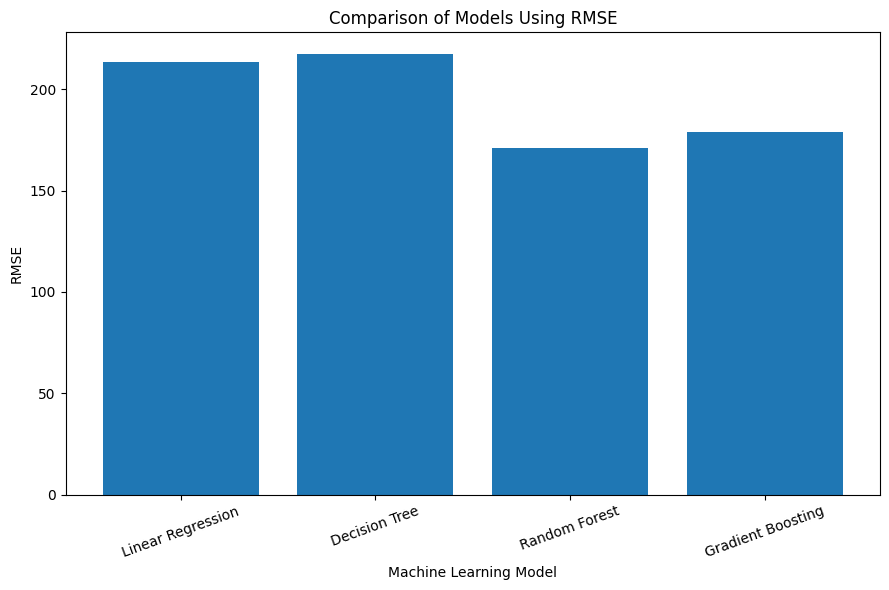

In [49]:
plt.figure(figsize=(9, 6))

plt.bar(
    results_df["Model"],
    results_df["RMSE"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE")

plt.title("Comparison of Models Using RMSE")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [50]:
# STEP 13: SELECT BEST MODEL


best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(),
    "Model"
]

print("Best Model:")
print(best_model_name)

Best Model:
Random Forest


In [51]:
trained_models = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

best_model = trained_models[best_model_name]

print("\nSelected model:")
print(best_model_name)


Selected model:
Random Forest


In [52]:
import os

base_path = r"F:\25.2F HND\ML CW\Fish_Price_Prediction"

models_path = os.path.join(
    base_path,
    "models"
)

results_path = os.path.join(
    base_path,
    "outputs",
    "results"
)

figures_path = os.path.join(
    base_path,
    "outputs",
    "figures"
)

os.makedirs(models_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)
os.makedirs(figures_path, exist_ok=True)

In [53]:
# SAVE BEST MODEL

model_file = os.path.join(
    models_path,
    "best_model.pkl"
)

joblib.dump(
    best_model,
    model_file
)

print("Best model saved:")
print(model_file)

Best model saved:
F:\25.2F HND\ML CW\Fish_Price_Prediction\models\best_model.pkl


In [54]:
model_name_file = os.path.join(
    models_path,
    "best_model_name.txt"
)

with open(model_name_file, "w") as f:
    f.write(best_model_name)

print("Model name saved.")

Model name saved.


In [55]:
evaluation_file = os.path.join(
    results_path,
    "model_evaluation.csv"
)

results_df.to_csv(
    evaluation_file,
    index=False
)

print("Evaluation results saved:")
print(evaluation_file)

Evaluation results saved:
F:\25.2F HND\ML CW\Fish_Price_Prediction\outputs\results\model_evaluation.csv


In [56]:
best_predictions = best_model.predict(
    X_test
)

In [57]:
prediction_results = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": best_predictions
})

display(
    prediction_results.head(15)
)

,Actual_Price,Predicted_Price
0,1800.00,1720.053023
1,1433.33,1341.451701
2,1175.00,1140.488122
3,1725.00,1578.552727
4,1325.00,1149.640272
5,1990.00,2071.067285
6,1557.14,1443.190965
7,1100.00,1102.404168
8,860.00,843.620260
9,800.00,758.942313


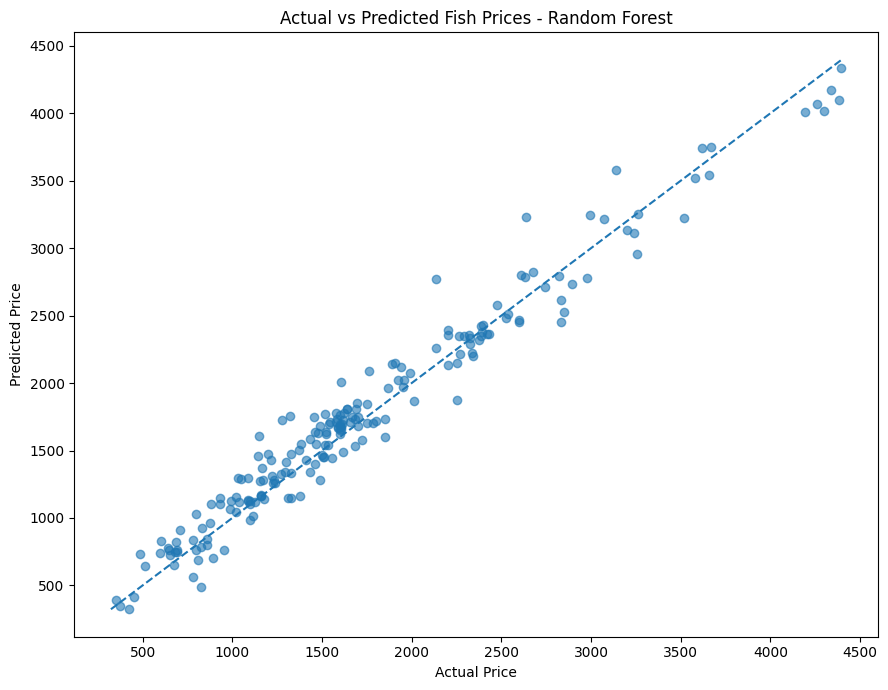

In [58]:
plt.figure(figsize=(9, 7))

plt.scatter(
    prediction_results["Actual_Price"],
    prediction_results["Predicted_Price"],
    alpha=0.6
)

min_price = min(
    prediction_results["Actual_Price"].min(),
    prediction_results["Predicted_Price"].min()
)

max_price = max(
    prediction_results["Actual_Price"].max(),
    prediction_results["Predicted_Price"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title(
    f"Actual vs Predicted Fish Prices - {best_model_name}"
)

plt.tight_layout()

plt.show()

In [59]:
actual_predicted_file = os.path.join(
    figures_path,
    "actual_vs_predicted.png"
)

plt.savefig(
    actual_predicted_file,
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [60]:
prediction_file = os.path.join(
    results_path,
    "prediction_results.csv"
)

prediction_results.to_csv(
    prediction_file,
    index=False
)

print("Prediction results saved:")
print(prediction_file)

Prediction results saved:
F:\25.2F HND\ML CW\Fish_Price_Prediction\outputs\results\prediction_results.csv


In [61]:
print("Selected model:")
print(best_model_name)


Selected model:
Random Forest


In [62]:

# FEATURE IMPORTANCE

model = best_model.named_steps["model"]

fitted_preprocessor = (
    best_model.named_steps["preprocessor"]
)

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

importances = model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
)

display(
    feature_importance_df.head(20)
)

,Feature,Importance
36,numerical__Price_LastWeek,0.921221
35,numerical__Price_2025,0.063311
33,numerical__MonthNumber,0.003356
34,numerical__Week,0.002738
25,categorical__Species_Seer,0.001694
0,categorical__MarketType_Consumer,0.000751
17,categorical__Species_Prawns,0.000727
1,categorical__MarketType_Wholesale,0.000626
14,categorical__Species_Marlins,0.000482
9,categorical__Species_Indian Anchovies,0.000420


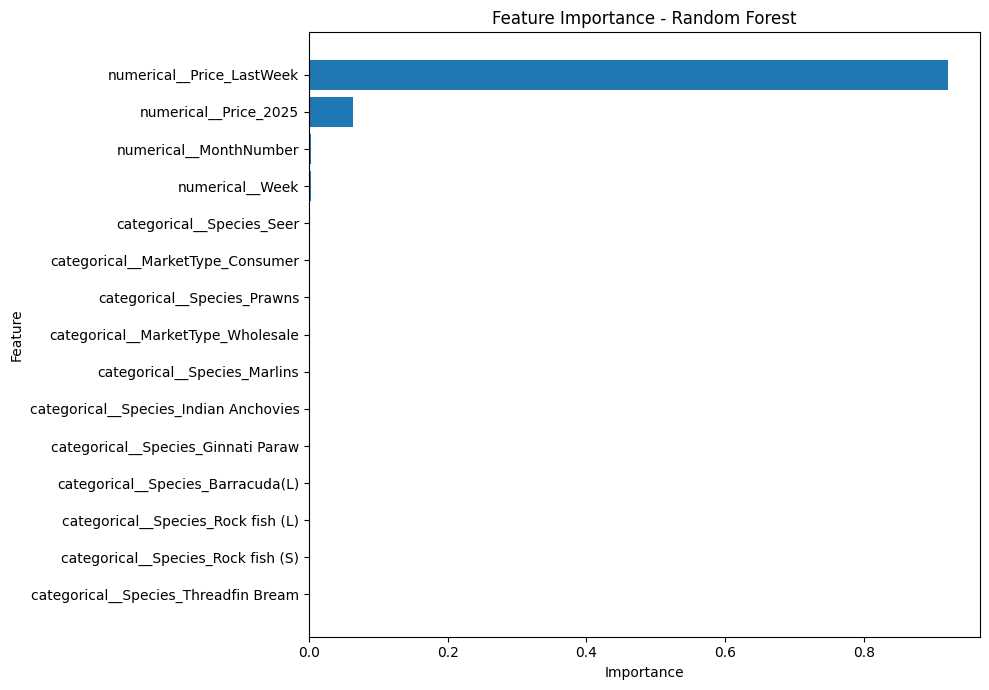

In [63]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    f"Feature Importance - {best_model_name}"
)

plt.tight_layout()

plt.show()

In [64]:
feature_file = os.path.join(
    figures_path,
    "feature_importance.png"
)

plt.savefig(
    feature_file,
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [65]:
importance_csv = os.path.join(
    results_path,
    "feature_importance.csv"
)

feature_importance_df.to_csv(
    importance_csv,
    index=False
)

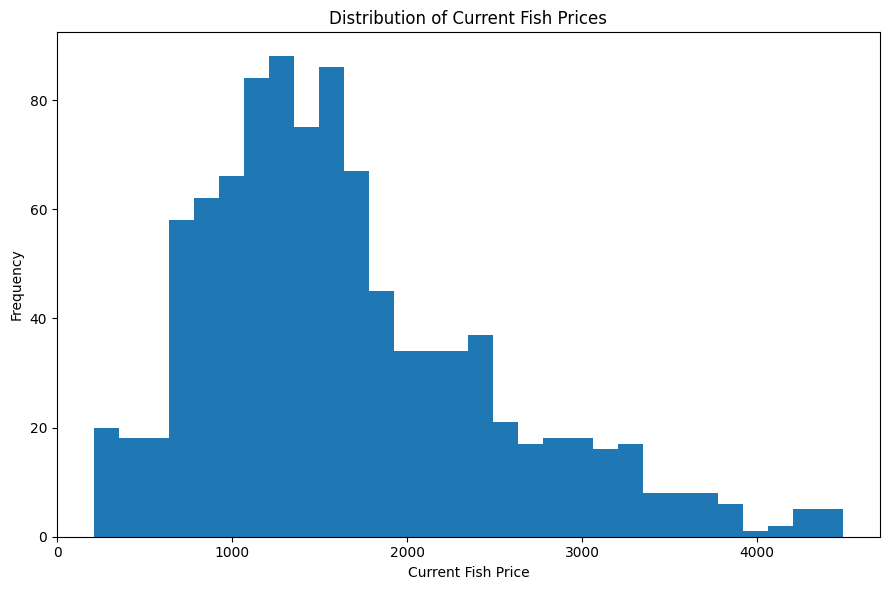

In [66]:
# Price Distribution
plt.figure(figsize=(9, 6))

plt.hist(
    df["Price_Current"],
    bins=30
)

plt.xlabel("Current Fish Price")
plt.ylabel("Frequency")

plt.title(
    "Distribution of Current Fish Prices"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_path,
        "price_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

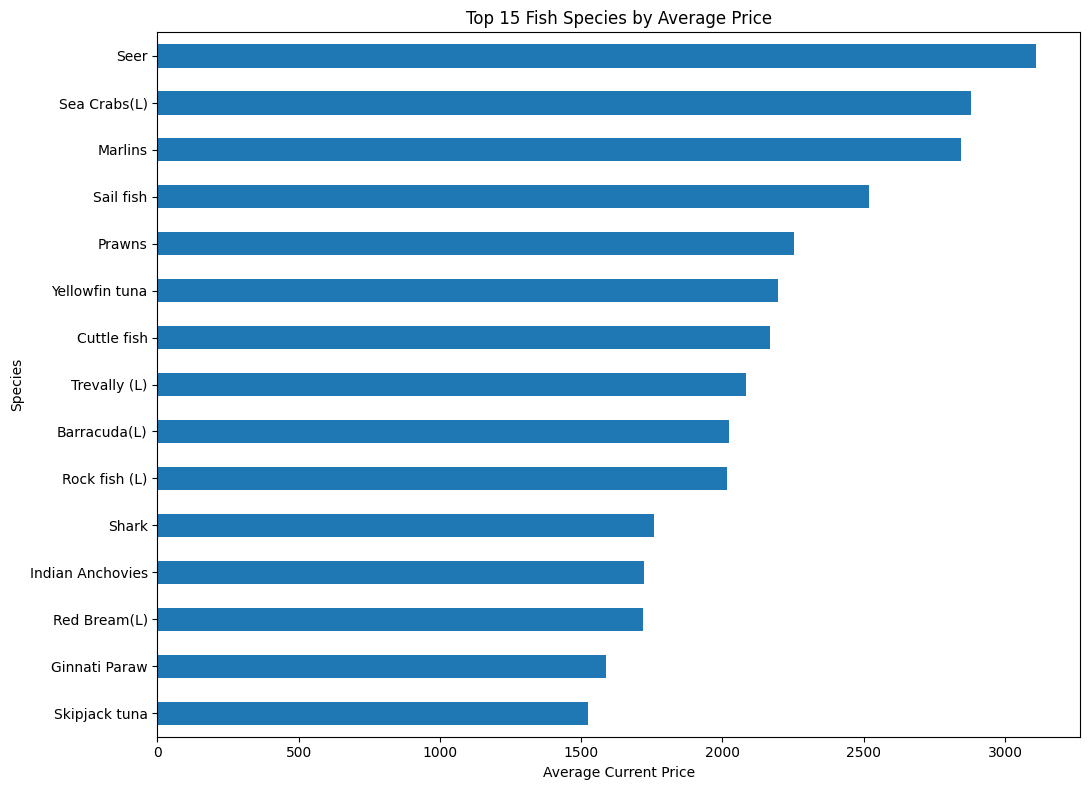

In [67]:
# Species Comparison
species_prices = (
    df.groupby("Species")["Price_Current"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 8))

species_prices.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Average Current Price")
plt.ylabel("Species")

plt.title(
    "Top 15 Fish Species by Average Price"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_path,
        "species_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

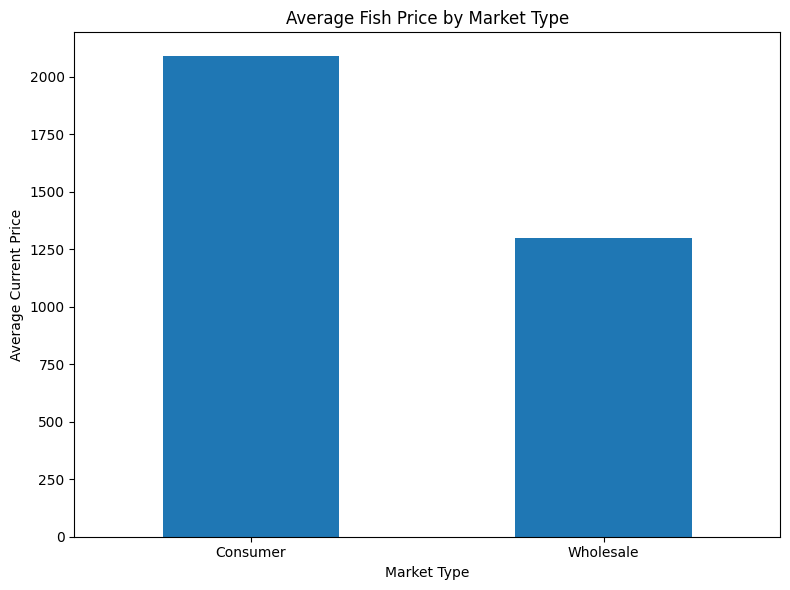

In [68]:
# ,Market Comparison
market_prices = (
    df.groupby("MarketType")["Price_Current"]
    .mean()
)

plt.figure(figsize=(8, 6))

market_prices.plot(
    kind="bar"
)

plt.xlabel("Market Type")
plt.ylabel("Average Current Price")

plt.title(
    "Average Fish Price by Market Type"
)

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_path,
        "market_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

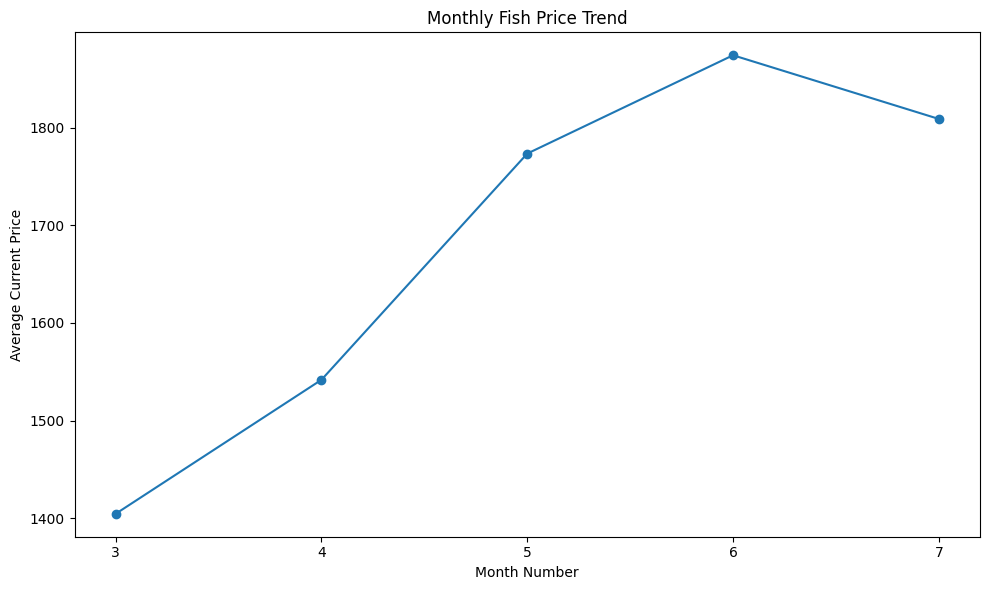

In [69]:
# Monthly Trend
monthly_prices = (
    df.groupby("MonthNumber")["Price_Current"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(10, 6))

plt.plot(
    monthly_prices.index,
    monthly_prices.values,
    marker="o"
)

plt.xlabel("Month Number")
plt.ylabel("Average Current Price")

plt.title(
    "Monthly Fish Price Trend"
)

plt.xticks(
    sorted(df["MonthNumber"].unique())
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_path,
        "monthly_trend.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
# Correlation Matrix
numeric_columns = [
    "MonthNumber",
    "Week",
    "Price_2025",
    "Price_LastWeek",
    "Price_Current"
]

correlation_matrix = (
    df[numeric_columns].corr()
)

display(correlation_matrix)

,MonthNumber,Week,Price_2025,Price_LastWeek,Price_Current
MonthNumber,1.000000,-0.079053,0.155627,0.195425,0.192691
Week,-0.079053,1.000000,0.015604,-0.026434,-0.032101
Price_2025,0.155627,0.015604,1.000000,0.903804,0.907670
Price_LastWeek,0.195425,-0.026434,0.903804,1.000000,0.979365
Price_Current,0.192691,-0.032101,0.907670,0.979365,1.000000


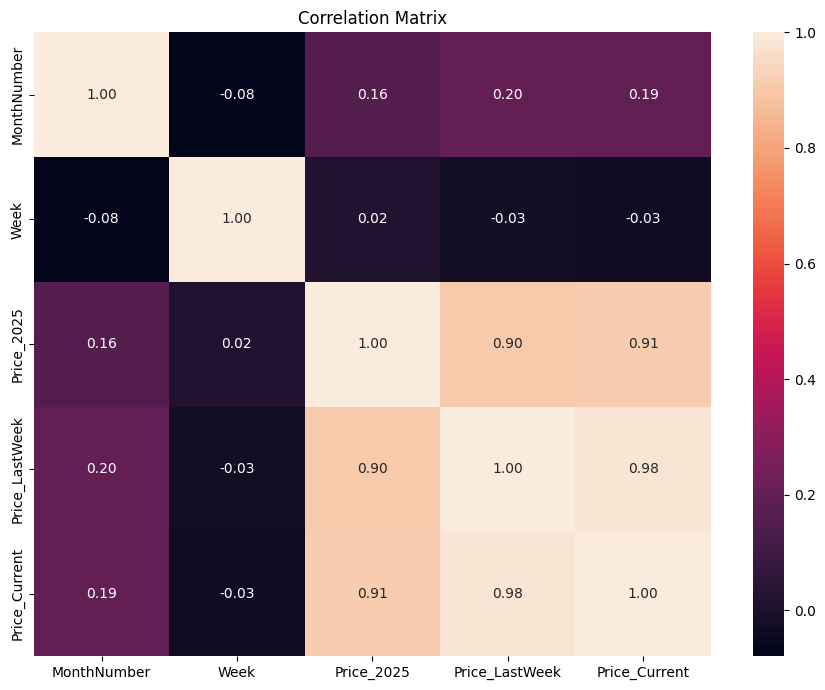

In [71]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title(
    "Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_path,
        "correlation_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

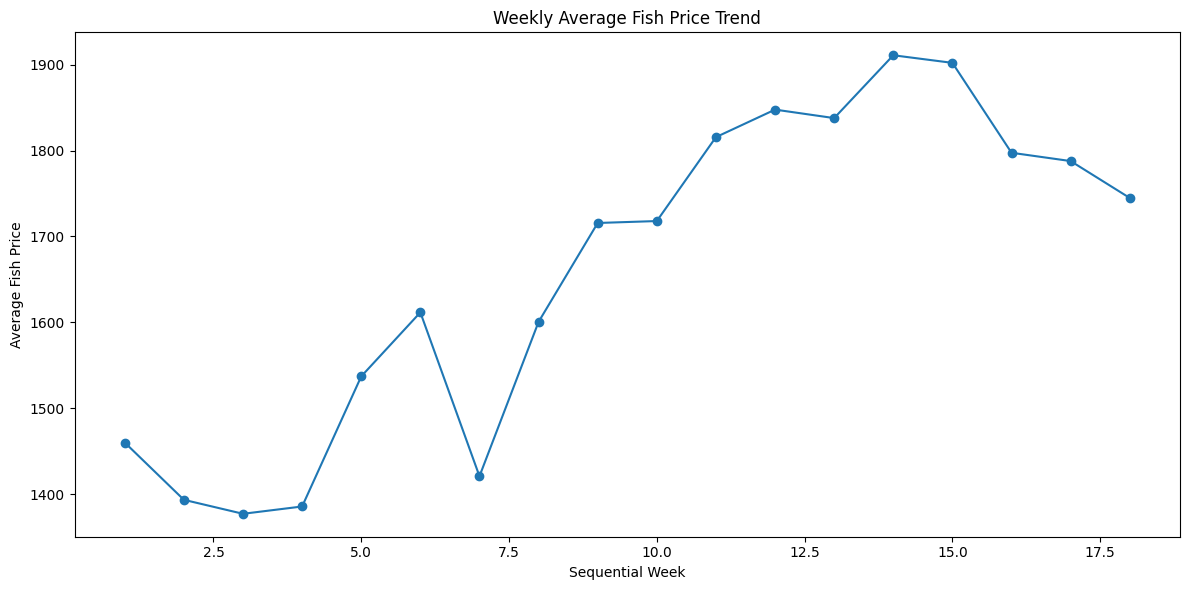

In [72]:
# Weekly Trend
weekly_prices = (
    df.groupby(
        ["Year", "MonthNumber", "Week"]
    )["Price_Current"]
    .mean()
    .reset_index()
)

weekly_prices["Time_Index"] = range(
    1,
    len(weekly_prices) + 1
)

plt.figure(figsize=(12, 6))

plt.plot(
    weekly_prices["Time_Index"],
    weekly_prices["Price_Current"],
    marker="o"
)

plt.xlabel("Sequential Week")
plt.ylabel("Average Fish Price")

plt.title(
    "Weekly Average Fish Price Trend"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_path,
        "weekly_trend.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [73]:
display(results_df)

,Model,MAE,RMSE,R2
0,Linear Regression,171.787799,213.367412,0.938535
1,Decision Tree,177.345575,217.276154,0.936263
2,Random Forest,133.125495,171.222615,0.960418
3,Gradient Boosting,138.317472,179.094213,0.956695
